In [21]:
!pip install tensorflow scikit-learn imbalanced-learn pandas numpy matplotlib seaborn -q

In [23]:
#imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings, pickle
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, roc_auc_score, roc_curve,
                             ConfusionMatrixDisplay, f1_score)
from sklearn.utils.class_weight import compute_class_weight
from imblearn.over_sampling import SMOTE

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization, LeakyReLU
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.regularizers import l2

print("TensorFlow:", tf.__version__)
print("All imports successful!")

TensorFlow: 2.20.0
All imports successful!


In [24]:
# Load dataset
df = pd.read_csv('/content/Churn_Modelling.csv')
print("Shape:", df.shape)
df.head()

Shape: (10000, 14)


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [25]:
#Basic info
print("=== Missing Values ===")
print(df.isnull().sum())
print(f"\nChurn rate: {df['Exited'].mean()*100:.2f}%")
print("\nClass distribution:")
print(df['Exited'].value_counts())

=== Missing Values ===
RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

Churn rate: 20.37%

Class distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


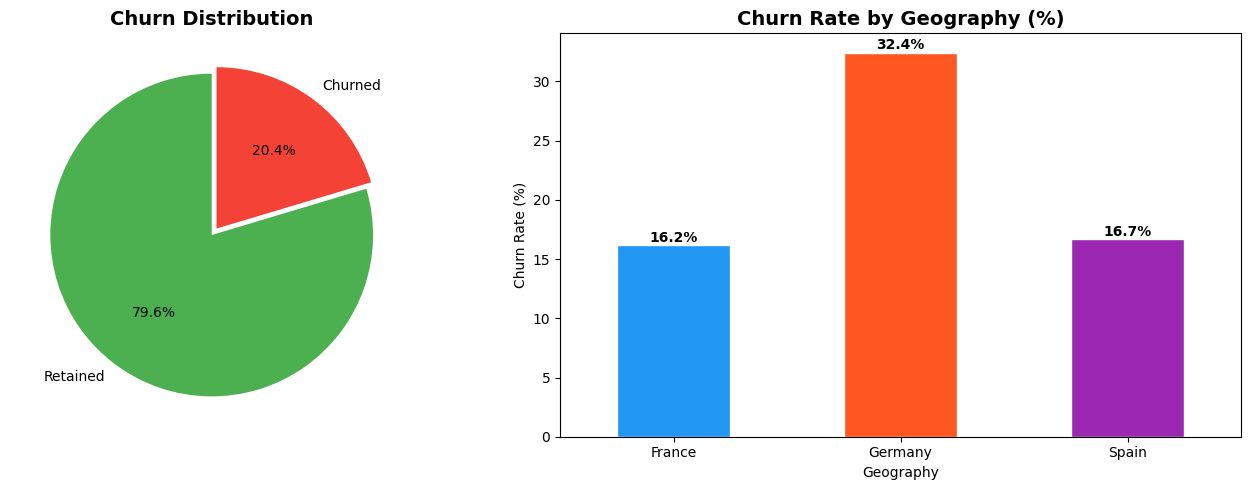

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df['Exited'].value_counts().plot.pie(
    ax=axes[0], autopct='%1.1f%%',
    labels=['Retained', 'Churned'],
    colors=['#4CAF50', '#F44336'],
    startangle=90, explode=(0, 0.05)
)
axes[0].set_title('Churn Distribution', fontsize=14, fontweight='bold')
axes[0].set_ylabel('')

geo_churn = df.groupby('Geography')['Exited'].mean() * 100
geo_churn.plot.bar(ax=axes[1], color=['#2196F3','#FF5722','#9C27B0'], rot=0, edgecolor='white')
axes[1].set_title('Churn Rate by Geography (%)', fontsize=14, fontweight='bold')
axes[1].set_ylabel('Churn Rate (%)')
for i, v in enumerate(geo_churn):
    axes[1].text(i, v+0.3, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_01.png', dpi=150, bbox_inches='tight')
plt.show()

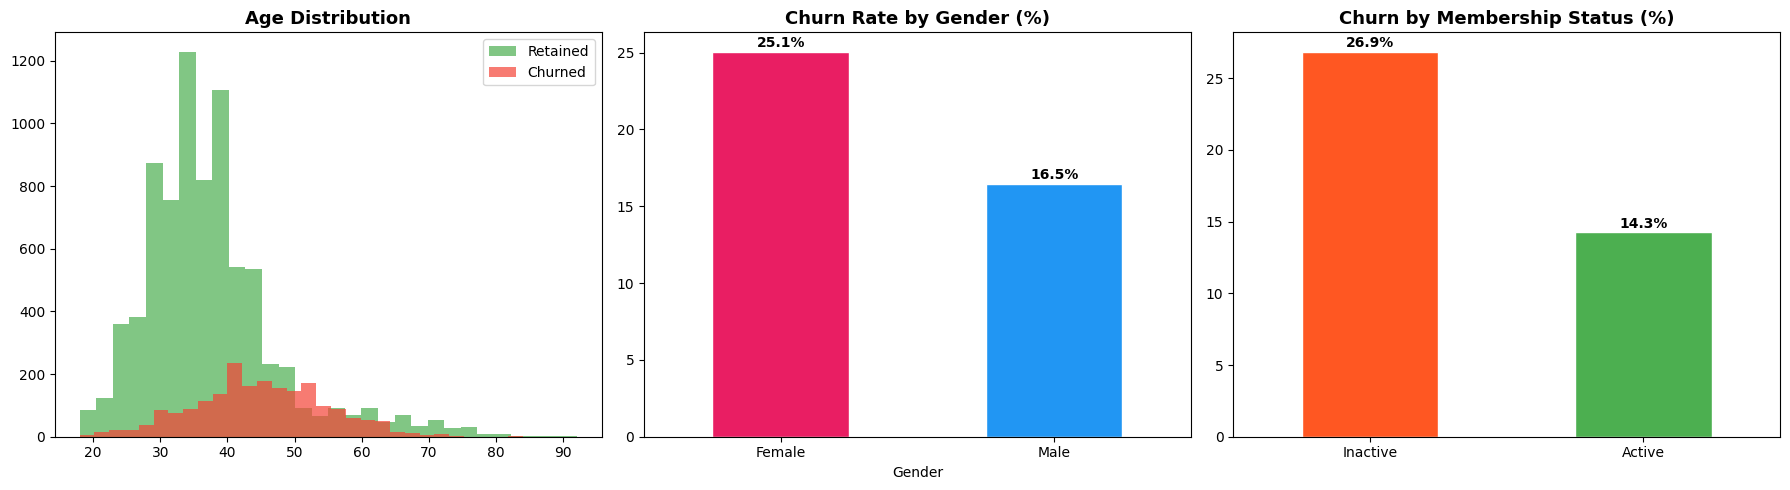

In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

axes[0].hist(df[df['Exited']==0]['Age'], bins=30, alpha=0.7, color='#4CAF50', label='Retained')
axes[0].hist(df[df['Exited']==1]['Age'], bins=30, alpha=0.7, color='#F44336', label='Churned')
axes[0].set_title('Age Distribution', fontsize=13, fontweight='bold')
axes[0].legend()

gender_churn = df.groupby('Gender')['Exited'].mean() * 100
gender_churn.plot.bar(ax=axes[1], color=['#E91E63','#2196F3'], rot=0, edgecolor='white')
axes[1].set_title('Churn Rate by Gender (%)', fontsize=13, fontweight='bold')
for i, v in enumerate(gender_churn):
    axes[1].text(i, v+0.3, f'{v:.1f}%', ha='center', fontweight='bold')

active_churn = df.groupby('IsActiveMember')['Exited'].mean() * 100
active_churn.index = ['Inactive', 'Active']
active_churn.plot.bar(ax=axes[2], color=['#FF5722','#4CAF50'], rot=0, edgecolor='white')
axes[2].set_title('Churn by Membership Status (%)', fontsize=13, fontweight='bold')
for i, v in enumerate(active_churn):
    axes[2].text(i, v+0.3, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_02.png', dpi=150, bbox_inches='tight')
plt.show()

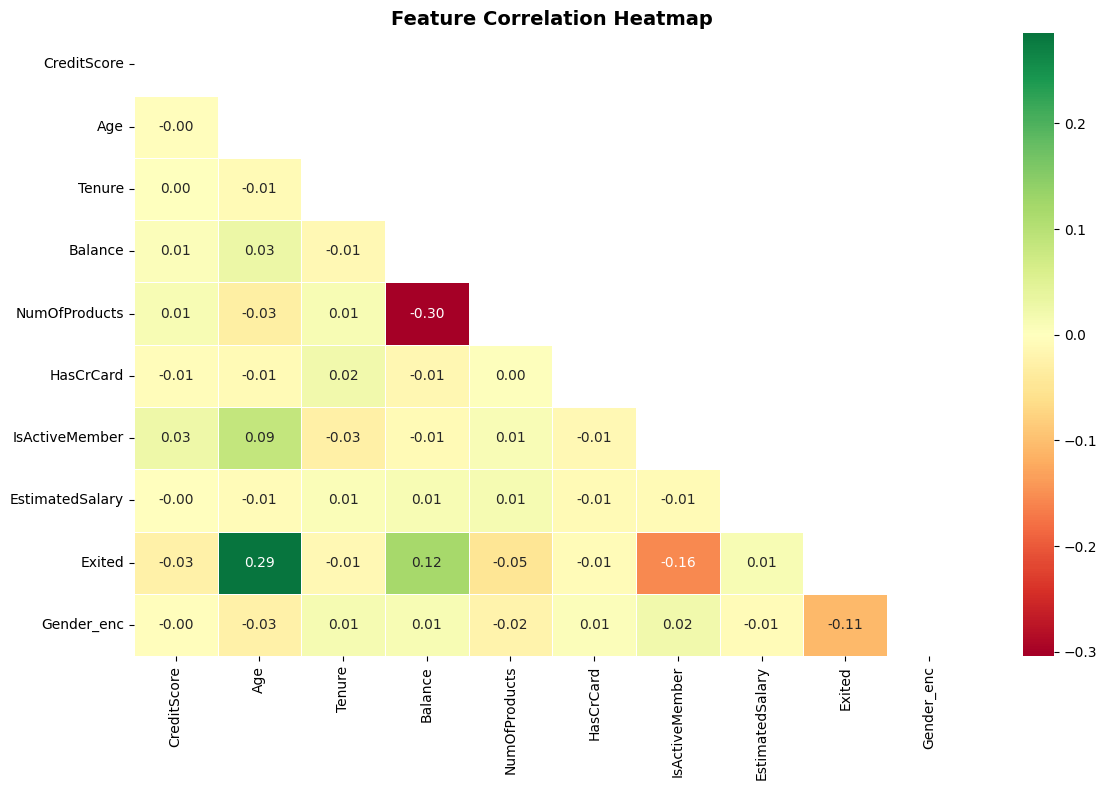

In [28]:
plt.figure(figsize=(12, 8))
temp = df.drop(columns=['RowNumber','CustomerId','Surname'])
temp['Gender_enc'] = LabelEncoder().fit_transform(temp['Gender'])
temp = temp.drop(columns=['Gender','Geography'])

corr = temp.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn',
            center=0, mask=mask, linewidths=0.5, annot_kws={'size':10})
plt.title('Feature Correlation Heatmap', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('eda_03.png', dpi=150, bbox_inches='tight')
plt.show()

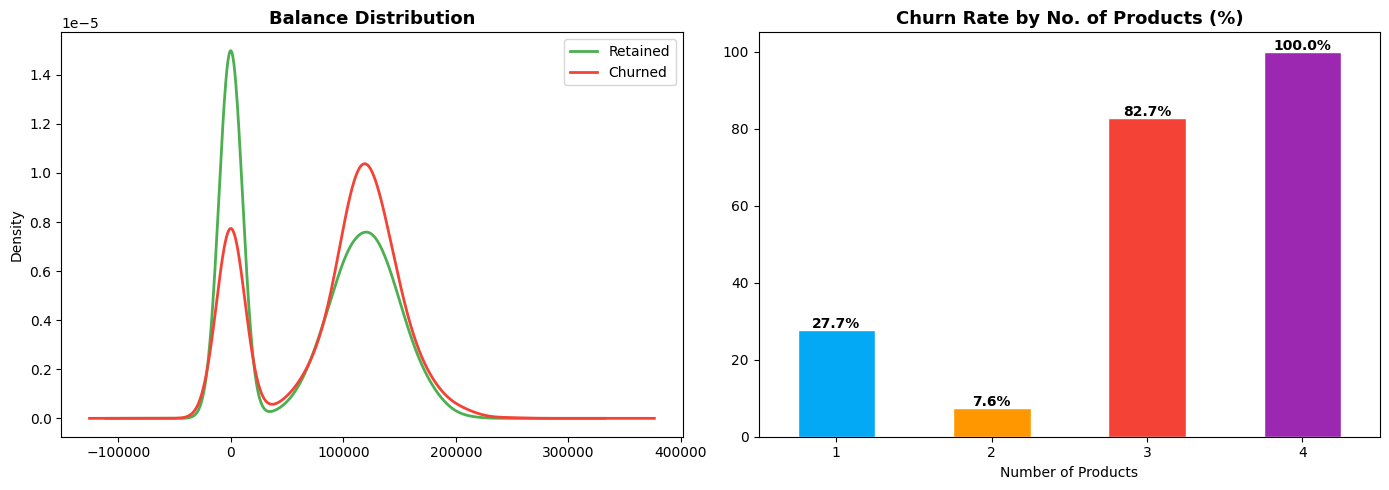

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for label, color, name in [(0,'#4CAF50','Retained'),(1,'#F44336','Churned')]:
    df[df['Exited']==label]['Balance'].plot.kde(ax=axes[0], color=color, label=name, linewidth=2)
axes[0].set_title('Balance Distribution', fontsize=13, fontweight='bold')
axes[0].legend()

prod_churn = df.groupby('NumOfProducts')['Exited'].mean() * 100
prod_churn.plot.bar(ax=axes[1], color=['#03A9F4','#FF9800','#F44336','#9C27B0'], rot=0, edgecolor='white')
axes[1].set_title('Churn Rate by No. of Products (%)', fontsize=13, fontweight='bold')
axes[1].set_xlabel('Number of Products')
for i, v in enumerate(prod_churn):
    axes[1].text(i, v+0.5, f'{v:.1f}%', ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('eda_04.png', dpi=150, bbox_inches='tight')
plt.show()

In [30]:
# Drop irrelevant columns
df.drop(columns=['RowNumber', 'CustomerId', 'Surname'], inplace=True)

# ── New engineered features ──────────────────────────────────
df['BalanceSalaryRatio']  = df['Balance'] / (df['EstimatedSalary'] + 1)
df['AgeGroup']            = pd.cut(df['Age'],
                                bins=[0, 30, 40, 50, 60, 100],
                                labels=[0, 1, 2, 3, 4]).astype(int)
df['TenureAgeRatio']      = df['Tenure'] / (df['Age'] + 1)
df['ProductsPerTenure']   = df['NumOfProducts'] / (df['Tenure'] + 1)
df['IsHighValueCustomer'] = ((df['Balance'] > df['Balance'].median()) &
                              (df['NumOfProducts'] >= 2)).astype(int)
df['ZeroBalance']         = (df['Balance'] == 0).astype(int)

# ── Encode categorical columns ───────────────────────────────
df['Gender'] = LabelEncoder().fit_transform(df['Gender'])
df = pd.get_dummies(df, columns=['Geography'], drop_first=False)

for col in ['Geography_France', 'Geography_Germany', 'Geography_Spain']:
    if col not in df.columns:
        df[col] = 0

print("Final columns:", list(df.columns))
print("Shape:", df.shape)

Final columns: ['CreditScore', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'BalanceSalaryRatio', 'AgeGroup', 'TenureAgeRatio', 'ProductsPerTenure', 'IsHighValueCustomer', 'ZeroBalance', 'Geography_France', 'Geography_Germany', 'Geography_Spain']
Shape: (10000, 19)


In [31]:
feature_cols = [
    'CreditScore', 'Gender', 'Age', 'Tenure', 'Balance',
    'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary',
    'Geography_France', 'Geography_Germany', 'Geography_Spain',
    'BalanceSalaryRatio', 'AgeGroup', 'TenureAgeRatio',
    'ProductsPerTenure', 'IsHighValueCustomer', 'ZeroBalance'
]

X = df[feature_cols].values
y = df['Exited'].values

print(f"Features : {len(feature_cols)}")
print(f"X shape  : {X.shape}")
print(f"y shape  : {y.shape}")

Features : 18
X shape  : (10000, 18)
y shape  : (10000,)


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled  = scaler.transform(X_test)

print(f"Train : {X_train_scaled.shape}")
print(f"Test  : {X_test_scaled.shape}")

Train : (8000, 18)
Test  : (2000, 18)


In [33]:
print("Before SMOTE:", np.bincount(y_train))

smote = SMOTE(random_state=42, k_neighbors=5)
X_train_res, y_train_res = smote.fit_resample(X_train_scaled, y_train)

print("After SMOTE :", np.bincount(y_train_res))

Before SMOTE: [6370 1630]
After SMOTE : [6370 6370]


In [34]:
def build_model(input_dim):
    model = Sequential([
        Dense(512, input_dim=input_dim, kernel_initializer='he_uniform',
              kernel_regularizer=l2(0.001)),
        LeakyReLU(alpha=0.1),
        BatchNormalization(),
        Dropout(0.4),

        Dense(256, kernel_initializer='he_uniform', kernel_regularizer=l2(0.001)),
        LeakyReLU(alpha=0.1),
        BatchNormalization(),
        Dropout(0.4),

        Dense(128, kernel_initializer='he_uniform', kernel_regularizer=l2(0.001)),
        LeakyReLU(alpha=0.1),
        BatchNormalization(),
        Dropout(0.3),

        Dense(64, kernel_initializer='he_uniform'),
        LeakyReLU(alpha=0.1),
        BatchNormalization(),
        Dropout(0.2),

        Dense(32, kernel_initializer='he_uniform'),
        LeakyReLU(alpha=0.1),
        Dropout(0.1),

        Dense(1, activation='sigmoid')
    ])

    model.compile(
        optimizer=Adam(learning_rate=0.0005),
        loss='binary_crossentropy',
        metrics=['accuracy',
                 tf.keras.metrics.AUC(name='auc'),
                 tf.keras.metrics.Precision(name='precision'),
                 tf.keras.metrics.Recall(name='recall')]
    )
    return model

model = build_model(input_dim=X_train_res.shape[1])
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_11 (Dense)                │ (None, 512)            │         9,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 512)            │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_9 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_8           │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_10 (Dropout)            │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_9           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_11 (Dropout)            │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_10          │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_12 (Dropout)            │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_15 (Dense)                │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_13 (Dropout)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 188,161 (735.00 KB)

 Trainable params: 186,241 (727.50 KB)

 Non-trainable params: 1,920 (7.50 KB)

In [35]:
callbacks = [
    EarlyStopping(monitor='val_auc', patience=30,
                  restore_best_weights=True, mode='max', verbose=1),
    ReduceLROnPlateau(monitor='val_auc', factor=0.3,
                      patience=10, min_lr=1e-7, mode='max', verbose=1),
    ModelCheckpoint(filepath='best_model.keras', monitor='val_auc',
                    save_best_only=True, mode='max', verbose=0)
]

history = model.fit(
    X_train_res, y_train_res,
    validation_data=(X_test_scaled, y_test),
    epochs=300,
    batch_size=64,
    callbacks=callbacks,
    verbose=1
)
print("Training complete!")

Epoch 1/300
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.6683 - auc: 0.7297 - loss: 2.3877 - precision: 0.6449 - recall: 0.7491 - val_accuracy: 0.7490 - val_auc: 0.8305 - val_loss: 2.1461 - val_precision: 0.4320 - val_recall: 0.7420 - learning_rate: 5.0000e-04
Epoch 2/300
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 12ms/step - accuracy: 0.7220 - auc: 0.7947 - loss: 2.1507 - precision: 0.7152 - recall: 0.7377 - val_accuracy: 0.7585 - val_auc: 0.8424 - val_loss: 2.0016 - val_precision: 0.4454 - val_recall: 0.7617 - learning_rate: 5.0000e-04
Epoch 3/300
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 15ms/step - accuracy: 0.7419 - auc: 0.8234 - loss: 1.9851 - precision: 0.7384 - recall: 0.7493 - val_accuracy: 0.7815 - val_auc: 0.8546 - val_loss: 1.8454 - val_precision: 0.4766 - val_recall: 0.7494 - learning_rate: 5.0000e-04
Epoch 4/300
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.7547 - auc: 0.8326 - loss: 1.8484 - precision: 0.7561 - recall: 0.7520 - val_accuracy: 0.7780 - val_auc: 0.8581 - va

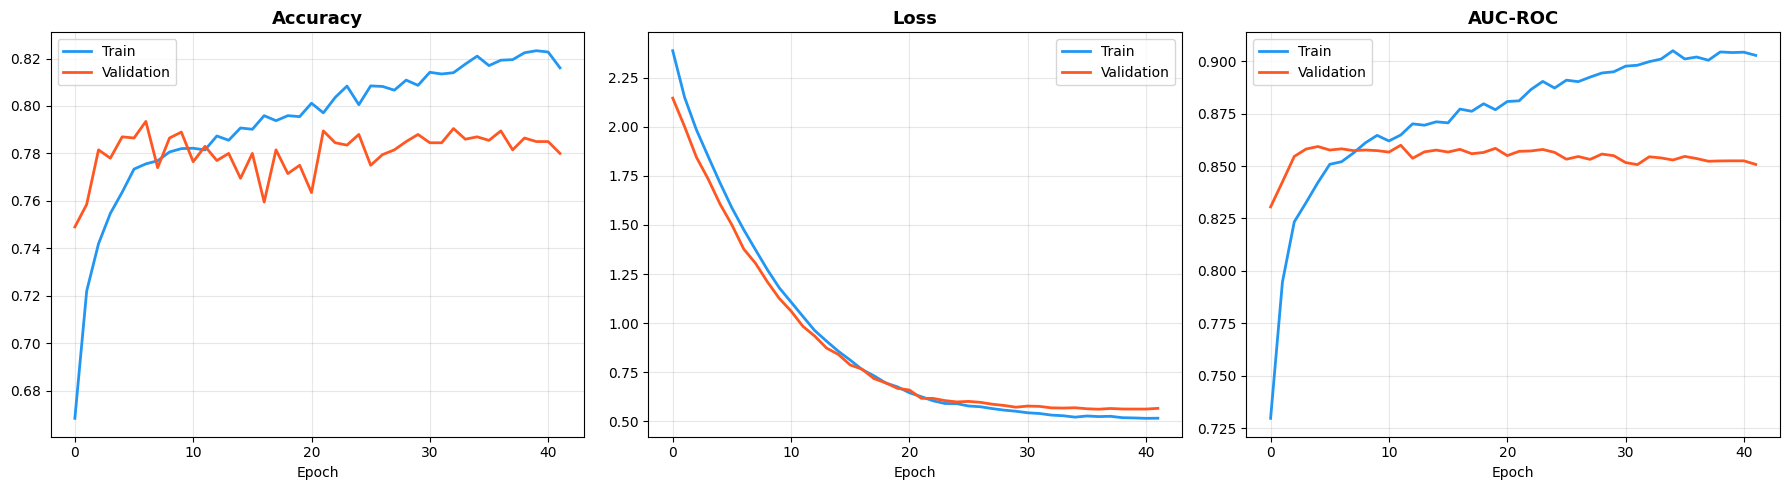

In [36]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, metric, title in zip(axes,
    ['accuracy', 'loss', 'auc'],
    ['Accuracy', 'Loss', 'AUC-ROC']):
    ax.plot(history.history[metric],     label='Train',      color='#2196F3', lw=2)
    ax.plot(history.history[f'val_{metric}'], label='Validation', color='#FF5722', lw=2)
    ax.set_title(title, fontsize=13, fontweight='bold')
    ax.set_xlabel('Epoch')
    ax.legend()
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig('training_curves.png', dpi=150, bbox_inches='tight')
plt.show()

63/63 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step
Best threshold : 0.68


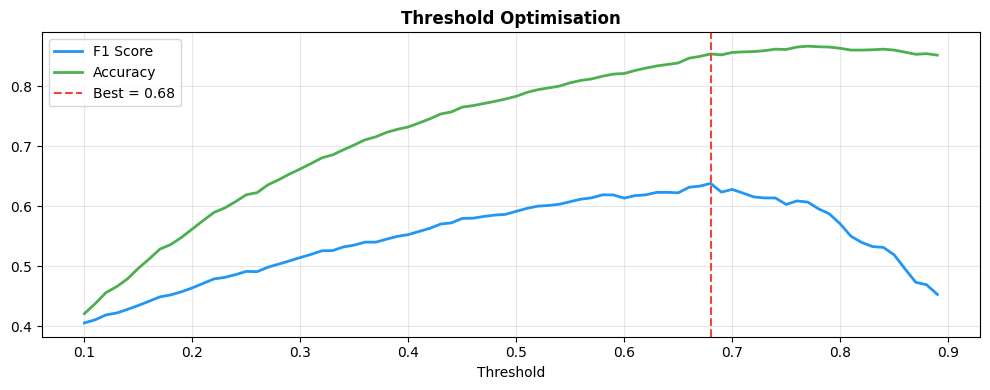

In [37]:
y_pred_prob = model.predict(X_test_scaled).flatten()

# Scan every threshold and pick the one with best F1
thresholds = np.arange(0.1, 0.9, 0.01)
f1_scores  = [f1_score(y_test, (y_pred_prob >= t).astype(int)) for t in thresholds]
acc_scores = [accuracy_score(y_test, (y_pred_prob >= t).astype(int)) for t in thresholds]

best_threshold = thresholds[np.argmax(f1_scores)]
print(f"Best threshold : {best_threshold:.2f}")

plt.figure(figsize=(10, 4))
plt.plot(thresholds, f1_scores,  label='F1 Score', color='#2196F3', lw=2)
plt.plot(thresholds, acc_scores, label='Accuracy',  color='#4CAF50', lw=2)
plt.axvline(best_threshold, color='#F44336', linestyle='--',
            label=f'Best = {best_threshold:.2f}')
plt.xlabel('Threshold')
plt.title('Threshold Optimisation', fontweight='bold')
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

  Threshold      : 0.68
  Test Accuracy  : 85.35%
  AUC-ROC        : 0.8599
              precision    recall  f1-score   support

    Retained       0.91      0.91      0.91      1593
     Churned       0.64      0.63      0.64       407

    accuracy                           0.85      2000
   macro avg       0.77      0.77      0.77      2000
weighted avg       0.85      0.85      0.85      2000



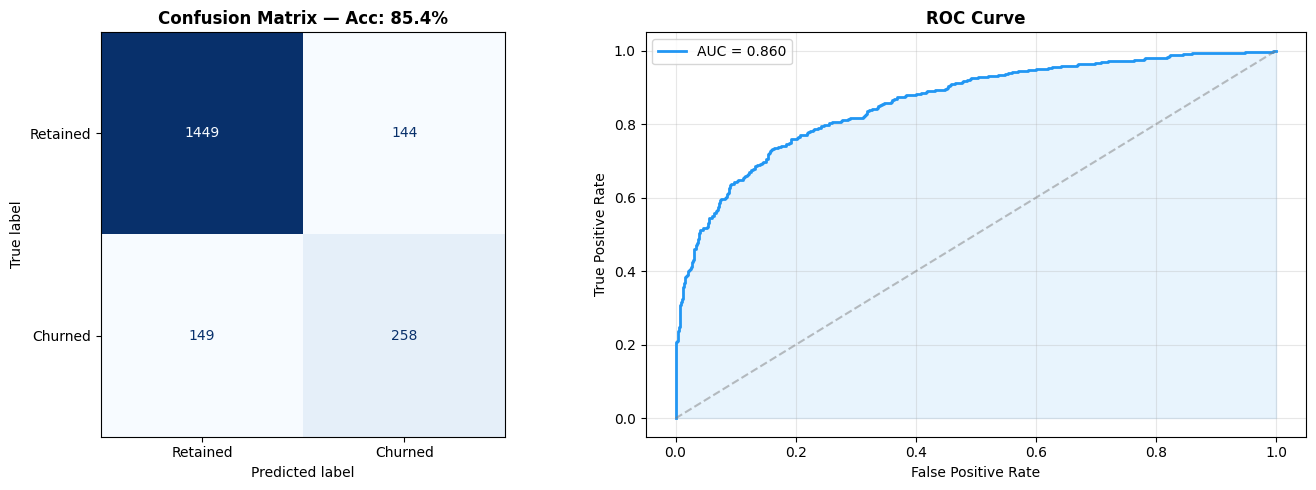

In [38]:
y_pred = (y_pred_prob >= best_threshold).astype(int)

acc = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_prob)

print("=" * 45)
print(f"  Threshold      : {best_threshold:.2f}")
print(f"  Test Accuracy  : {acc*100:.2f}%")
print(f"  AUC-ROC        : {auc:.4f}")
print("=" * 45)
print(classification_report(y_test, y_pred, target_names=['Retained','Churned']))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
    display_labels=['Retained','Churned']).plot(ax=axes[0], cmap='Blues', colorbar=False)
axes[0].set_title(f'Confusion Matrix — Acc: {acc*100:.1f}%', fontweight='bold')

fpr, tpr, _ = roc_curve(y_test, y_pred_prob)
axes[1].plot(fpr, tpr, color='#2196F3', lw=2, label=f'AUC = {auc:.3f}')
axes[1].plot([0,1],[0,1],'--', color='gray', alpha=0.5)
axes[1].fill_between(fpr, tpr, alpha=0.1, color='#2196F3')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve', fontweight='bold')
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

In [40]:
import shutil, pickle

# Save model in .keras format (correct for your Keras version)
model.save('churn_model.keras')
print("Model saved!")

with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
print("Scaler saved!")

with open('feature_cols.pkl', 'wb') as f:
    pickle.dump(feature_cols, f)
print("Feature cols saved!")

with open('threshold.pkl', 'wb') as f:
    pickle.dump(float(best_threshold), f)
print(f"Threshold saved: {best_threshold:.2f}")

print("\nAll files ready!")

Model saved!
Scaler saved!
Feature cols saved!
Threshold saved: 0.68

All files ready!


In [41]:
from google.colab import files

files.download('churn_model.keras')
files.download('scaler.pkl')
files.download('feature_cols.pkl')
files.download('threshold.pkl')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>